1. Identifikasi Atribut

In [136]:
#1
import pandas as pd

url = "https://raw.githubusercontent.com/isnanmulia/lecture-datasets/main/heart_modified.csv"

df = pd.read_csv(url)

print("Dataset berhasil dibaca!")
print("Ukuran dataset:", df.shape)

display(df.head())

Dataset berhasil dibaca!
Ukuran dataset: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172.0,N,0.0,Up,0
1,49,F,NAP,160.0,NaN,0,Normal,156.0,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98.0,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108.0,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122.0,N,0.0,Up,0


In [116]:
#2
print("TIPE DATA")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nJUMLAH NILAI UNIK")
print(df.nunique(dropna=True))

TIPE DATA
Age                 int64
Sex                object
ChestPainType      object
RestingBP         float64
Cholesterol       float64
FastingBS           int64
RestingECG         object
MaxHR             float64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

MISSING VALUES
Age                0
Sex                0
ChestPainType      0
RestingBP         18
Cholesterol       18
FastingBS          0
RestingECG         0
MaxHR             18
ExerciseAngina     0
Oldpeak            0
ST_Slope           0
HeartDisease       0
dtype: int64

JUMLAH NILAI UNIK
Age                50
Sex                 2
ChestPainType       4
RestingBP          67
Cholesterol       219
FastingBS           2
RestingECG          3
MaxHR             119
ExerciseAngina      2
Oldpeak            53
ST_Slope            3
HeartDisease        2
dtype: int64


In [117]:
#3
for kolom in df.columns:
    print("\nAtribut:", kolom)
    print("Nilai unik:", df[kolom].dropna().unique())
    print("Jumlah unik:", df[kolom].nunique())


Atribut: Age
Nilai unik: [40 49 37 48 54 39 45 58 42 38 43 60 36 44 53 52 51 56 41 32 65 35 59 50
 47 31 46 57 55 63 66 34 33 61 29 62 28 30 74 68 72 64 69 67 73 70 77 75
 76 71]
Jumlah unik: 50

Atribut: Sex
Nilai unik: ['M' 'F']
Jumlah unik: 2

Atribut: ChestPainType
Nilai unik: ['ATA' 'NAP' 'ASY' 'TA']
Jumlah unik: 4

Atribut: RestingBP
Nilai unik: [140. 160. 130. 138. 150. 120. 110. 136. 115. 100. 124. 113. 125. 145.
 112. 132. 118. 170. 142. 190. 135. 180. 108. 155. 128. 106.  92. 200.
 122.  98. 105. 133.  95.  80. 137. 185. 165. 126. 152. 116.   0. 144.
 154. 134. 104. 139. 131. 141. 178. 146. 158. 123. 102.  96. 143. 172.
 156. 114. 127. 101. 174.  94. 148. 117. 192. 129. 164.]
Jumlah unik: 67

Atribut: Cholesterol
Nilai unik: [289. 283. 214. 195. 339. 237. 208. 207. 284. 211. 164. 204. 234. 273.
 196. 201. 248. 267. 223. 184. 288. 215. 209. 260. 468. 188. 518. 167.
 224. 172. 186. 254. 306. 250. 177. 227. 230. 294. 264. 259. 175. 318.
 216. 340. 233. 205. 245. 180. 194. 270. 

In [118]:
#4
kategorik = [
    'Sex', 'ChestPainType', 'FastingBS',
    'RestingECG', 'ExerciseAngina',
    'ST_Slope', 'HeartDisease'
]

hasil = []

for kolom in df.columns:
    if kolom in kategorik:
        jenis = "Kategorik"
    else:
        jenis = "Numerik"

    hasil.append({
        'Atribut': kolom,
        'Jumlah Nilai Unik': df[kolom].nunique(),
        'Jenis': jenis,
        'Nilai Unik': (
            str(sorted(df[kolom].dropna().unique().tolist()))
            if kolom in kategorik else "-"
        )
    })

tabel_atribut = pd.DataFrame(hasil)
display(tabel_atribut)

,Atribut,Jumlah Nilai Unik,Jenis,Nilai Unik
0,Age,50,Numerik,-
1,Sex,2,Kategorik,"['F', 'M']"
2,ChestPainType,4,Kategorik,"['ASY', 'ATA', 'NAP', 'TA']"
3,RestingBP,67,Numerik,-
4,Cholesterol,219,Numerik,-
5,FastingBS,2,Kategorik,"[0, 1]"
6,RestingECG,3,Kategorik,"['LVH', 'Normal', 'ST']"
7,MaxHR,119,Numerik,-
8,ExerciseAngina,2,Kategorik,"['N', 'Y']"
9,Oldpeak,53,Numerik,-


2. Praproses data

In [119]:
#1
X = df.drop(columns=['HeartDisease'])
y = df['HeartDisease']

print("Data Prediktor:")
display(X.head())

print("Data Label:")
display(y.head())

Data Prediktor:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,40,M,ATA,140.0,289.0,0,Normal,172.0,N,0.0,Up
1,49,F,NAP,160.0,NaN,0,Normal,156.0,N,1.0,Flat
2,37,M,ATA,130.0,283.0,0,ST,98.0,N,0.0,Up
3,48,F,ASY,138.0,214.0,0,Normal,108.0,Y,1.5,Flat
4,54,M,NAP,150.0,195.0,0,Normal,122.0,N,0.0,Up


Data Label:


,HeartDisease
0,0
1,1
2,0
3,1
4,0


In [120]:
#2
print("STATISTIK SEBELUM PREPROCESSING")

display(X.describe(include='all').T)

STATISTIK SEBELUM PREPROCESSING


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,918.0,NaN,NaN,NaN,53.510893,9.432617,28.0,47.0,54.0,60.0,77.0
Sex,918,2,M,725,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ChestPainType,918,4,ASY,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RestingBP,900.0,NaN,NaN,NaN,132.411111,18.611534,0.0,120.0,130.0,140.0,200.0
Cholesterol,900.0,NaN,NaN,NaN,199.252222,109.644221,0.0,173.75,223.0,267.25,603.0
FastingBS,918.0,NaN,NaN,NaN,0.233115,0.423046,0.0,0.0,0.0,0.0,1.0
RestingECG,918,3,Normal,552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaxHR,900.0,NaN,NaN,NaN,136.874444,25.557038,60.0,120.0,138.0,156.0,202.0
ExerciseAngina,918,2,N,547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Oldpeak,918.0,NaN,NaN,NaN,0.887364,1.06657,-2.6,0.0,0.6,1.5,6.2


In [121]:
#3
from sklearn.impute import SimpleImputer

numerik = X.select_dtypes(include=np.number).columns.tolist()
kategorik_x = X.select_dtypes(exclude=np.number).columns.tolist()

imputer_num = SimpleImputer(strategy='mean')
imputer_cat = SimpleImputer(strategy='most_frequent')

X_num = pd.DataFrame(
    imputer_num.fit_transform(X[numerik]),
    columns=numerik
)

X_cat = pd.DataFrame(
    imputer_cat.fit_transform(X[kategorik_x]),
    columns=kategorik_x
)

X_bersih = pd.concat([X_num, X_cat], axis=1)

print("Missing values setelah imputasi:")
print(X_bersih.isnull().sum())

Missing values setelah imputasi:
Age               0
RestingBP         0
Cholesterol       0
FastingBS         0
MaxHR             0
Oldpeak           0
Sex               0
ChestPainType     0
RestingECG        0
ExerciseAngina    0
ST_Slope          0
dtype: int64


In [122]:
#4
X_encoded = pd.get_dummies(
    X_bersih,
    columns=kategorik_x,
    dtype=int
)

display(X_encoded.head())

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,Sex_F,Sex_M,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40.0,140.0,289.000000,0.0,172.0,0.0,0,1,0,1,0,0,0,1,0,1,0,0,0,1
1,49.0,160.0,199.252222,0.0,156.0,1.0,1,0,0,0,1,0,0,1,0,1,0,0,1,0
2,37.0,130.0,283.000000,0.0,98.0,0.0,0,1,0,1,0,0,0,0,1,1,0,0,0,1
3,48.0,138.0,214.000000,0.0,108.0,1.5,1,0,1,0,0,0,0,1,0,0,1,0,1,0
4,54.0,150.0,195.000000,0.0,122.0,0.0,0,1,0,0,1,0,0,1,0,1,0,0,0,1


In [123]:
#5
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_encoded),
    columns=X_encoded.columns
)

display(X_scaled.head())

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,Sex_F,Sex_M,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.412038,0.827141,-0.551341,1.388846,-0.832432,-0.515952,0.515952,-1.084138,2.075177,-0.532838,-0.229679,-0.507478,0.814275,-0.490449,0.823556,-0.823556,-0.271448,-1.002181,1.150674
1,-0.478484,1.497937,0.000000,-0.551341,0.756215,0.105664,1.938163,-1.938163,-1.084138,-0.481887,1.876744,-0.229679,-0.507478,0.814275,-0.490449,0.823556,-0.823556,-0.271448,0.997824,-0.869056
2,-1.751359,-0.130911,0.771843,-0.551341,-1.537075,-0.832432,-0.515952,0.515952,-1.084138,2.075177,-0.532838,-0.229679,-0.507478,-1.228087,2.038947,0.823556,-0.823556,-0.271448,-1.002181,1.150674
3,-0.584556,0.303448,0.135920,-0.551341,-1.141681,0.574711,1.938163,-1.938163,0.922392,-0.481887,-0.532838,-0.229679,-0.507478,0.814275,-0.490449,-1.214246,1.214246,-0.271448,0.997824,-0.869056
4,0.051881,0.954988,-0.039190,-0.551341,-0.588128,-0.832432,-0.515952,0.515952,-1.084138,-0.481887,1.876744,-0.229679,-0.507478,0.814275,-0.490449,0.823556,-0.823556,-0.271448,-1.002181,1.150674


In [124]:
#6
print("STATISTIK SETELAH PREPROCESSING")

display(X_scaled.describe().T)

STATISTIK SETELAH PREPROCESSING


,count,mean,std,min,25%,50%,75%,max
Age,918.0,-1.083616e-16,1.000545,-2.706015,-0.690629,0.051881,0.688318,2.491558
RestingBP,918.0,7.275710e-16,1.000545,-7.189253,-0.673860,-0.130911,0.412038,3.669734
Cholesterol,918.0,-3.096047e-17,1.000545,-1.836365,-0.218907,0.209650,0.622079,3.721053
FastingBS,918.0,-3.096047e-17,1.000545,-0.551341,-0.551341,-0.551341,-0.551341,1.813758
MaxHR,918.0,-7.894919e-16,1.000545,-3.039576,-0.667207,0.024734,0.716675,2.575031
Oldpeak,918.0,1.238419e-16,1.000545,-3.271482,-0.832432,-0.269575,0.574711,4.983762
Sex_F,918.0,7.740117e-18,1.000545,-0.515952,-0.515952,-0.515952,-0.515952,1.938163
Sex_M,918.0,-7.740117e-18,1.000545,-1.938163,0.515952,0.515952,0.515952,0.515952
ChestPainType_ASY,918.0,-1.741526e-16,1.000545,-1.084138,-1.084138,0.922392,0.922392,0.922392
ChestPainType_ATA,918.0,0.000000e+00,1.000545,-0.481887,-0.481887,-0.481887,-0.481887,2.075177


3. Model Klasifikasi

In [125]:
#1
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

print("Jumlah seluruh data:", len(X))
print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nPersentase Training:",
      round(len(X_train)/len(X)*100, 2), "%")

print("Persentase Testing:",
      round(len(X_test)/len(X)*100, 2), "%")

Jumlah seluruh data: 918
Jumlah data training: 780
Jumlah data testing: 138

Persentase Training: 84.97 %
Persentase Testing: 15.03 %


In [126]:
#2
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numerik = X.select_dtypes(include=np.number).columns.tolist()
kategorik_x = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ]), numerik),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), kategorik_x)
])

model_klasifikasi = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(
        C=1.0,
        solver='lbfgs',
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

print("Model Logistic Regression berhasil dibuat!")

Model Logistic Regression berhasil dibuat!


In [127]:
#3
model_klasifikasi.fit(X_train, y_train)

print("Model berhasil dilatih!")

Model berhasil dilatih!


In [128]:
#4
y_pred = model_klasifikasi.predict(X_test)

print("Hasil prediksi:")
print(y_pred)

print("\nLabel sebenarnya:")
print(y_test.to_numpy())

Hasil prediksi:
[0 1 1 1 0 1 0 0 0 1 0 0 0 1 0 1 0 1 0 1 1 1 1 0 1 0 1 1 0 1 1 0 0 1 0 1 1
 0 0 0 1 0 1 1 0 0 0 1 1 1 0 1 0 1 1 1 0 1 1 1 1 0 0 1 1 1 1 0 1 0 1 1 1 1
 1 1 0 1 0 1 1 0 1 1 1 1 1 1 0 1 1 0 0 1 1 1 0 1 1 0 1 0 1 1 1 0 0 1 0 1 0
 0 1 0 1 0 1 0 0 0 0 1 1 0 0 0 0 0 1 0 1 0 0 1 1 0 0 1]

Label sebenarnya:
[0 1 1 0 1 1 0 0 0 1 0 1 0 1 0 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 1 0 0 1 0 0 1
 0 0 0 1 0 1 1 0 0 0 0 1 1 0 1 0 1 1 1 0 1 1 1 1 0 0 1 1 0 0 0 1 0 1 1 1 1
 1 1 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 0 1 1 1 1 0 1 1 0 1 0 1 1 1 0 0 1 0 1 0
 0 1 0 1 1 1 0 0 0 0 1 1 0 0 0 0 0 1 0 0 1 0 1 1 0 0 1]


Confusion Matrix:
[[54  8]
 [ 7 69]]


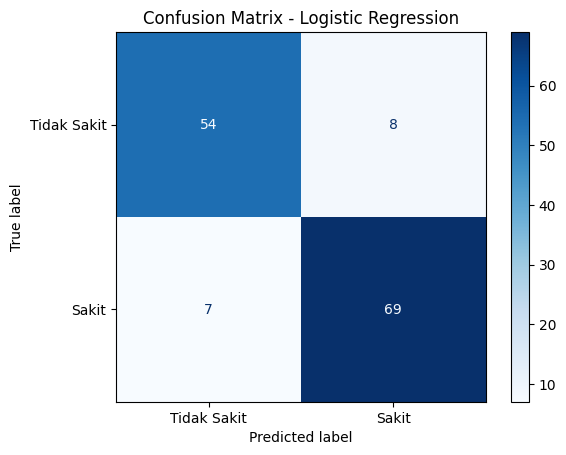

In [129]:
#5
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Tidak Sakit', 'Sakit']
)

display_matrix.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [130]:
#6
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

akurasi = accuracy_score(y_test, y_pred)

print("Accuracy:", round(akurasi, 4))
print("Accuracy (%):", round(akurasi * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8913
Accuracy (%): 89.13 %

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.87      0.88        62
           1       0.90      0.91      0.90        76

    accuracy                           0.89       138
   macro avg       0.89      0.89      0.89       138
weighted avg       0.89      0.89      0.89       138



4. Clustering


In [131]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerik = X.select_dtypes(include=np.number).columns.tolist()
kategorik_x = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor_cluster = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ]), numerik),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), kategorik_x)
])

X_cluster = preprocessor_cluster.fit_transform(X)

print("Preprocessing clustering berhasil!")
print("Jumlah data:", X_cluster.shape[0])
print("Jumlah fitur:", X_cluster.shape[1])

Preprocessing clustering berhasil!
Jumlah data: 918
Jumlah fitur: 20


In [132]:
model_cluster = AgglomerativeClustering(
    n_clusters=2,
    metric='euclidean',
    linkage='ward'
)

cluster_labels = model_cluster.fit_predict(X_cluster)

print("Clustering berhasil!")
print("Jumlah cluster:", len(set(cluster_labels)))

Clustering berhasil!
Jumlah cluster: 2


In [133]:
import numpy as np

sse = 0

for cluster in np.unique(cluster_labels):
    anggota = X_cluster[cluster_labels == cluster]

    centroid = anggota.mean(axis=0)
    jarak = anggota - centroid

    sse += np.sum(np.asarray(jarak) ** 2)

print("SSE:", round(sse, 4))

SSE: 6694.1557


In [134]:
from sklearn.metrics import silhouette_score

silhouette = silhouette_score(
    X_cluster,
    cluster_labels
)

print("Silhouette Score:", round(silhouette, 4))

Silhouette Score: 0.135


In [135]:
import pandas as pd

hasil_cluster = pd.Series(cluster_labels).value_counts().sort_index()

print("Jumlah anggota setiap cluster:")
print(hasil_cluster)

Jumlah anggota setiap cluster:
0    558
1    360
Name: count, dtype: int64
